# Notebook 9 — Did the manipulation change firing rate?

**Summer course: data-analysis pitfalls**

We recorded 40 units and optogenetically suppressed a long-range input to the
area, in blocks interleaved with control blocks, giving 10 minutes of laser-off
and 10 minutes of laser-on per unit. Every unit is measured in both conditions,
so this is a **paired** design and the paired t-test is the obvious tool.

> ### The claim
> *"The manipulation had no detectable effect on firing rate: 9.31 spikes/s with
> the laser off versus 9.02 with it on (paired t-test, t = -0.48, p = 0.63,
> n = 40 units). We therefore find no evidence that this input drives the area."*

Run it and you'll get exactly that.

**The claim is false. The manipulation really does suppress firing, substantially
and in most units.** Your job is to work out why the paired t-test could not see
it. Note that this is the opposite failure from most of the notebooks in this
course: the test is not inventing an effect, it is missing a real one.

`hints.md` has guiding questions and `notebook9_solution.ipynb` has the answer.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams['font.family']       = 'Arial'
plt.rcParams['font.sans-serif']   = ['Arial', 'DejaVu Sans']
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['pdf.fonttype']      = 42
plt.rcParams['ps.fonttype']       = 42

C_OFF, C_ON = '0.35', 'tab:purple'


In [2]:
d = np.load('data/data.npz')
counts_off = d['counts_off']            # (units,) spikes with the laser off
counts_on  = d['counts_on']             # (units,) spikes with the laser on
duration   = float(d['duration'])       # s spent in EACH condition

off = counts_off / duration             # spikes/s, one number per unit
on  = counts_on  / duration
n_units = off.size
print(f'{n_units} units, {duration/60:.0f} min per condition')
print(f'baseline rates: median {np.median(off):.2f}, '
      f'range {off.min():.2f} to {off.max():.1f} spikes/s')


40 units, 10 min per condition
baseline rates: median 3.14, range 0.11 to 82.3 spikes/s


## Step 1 — The standard summary and the paired test

On the left, condition means with SEM error bars. On the right, every unit as a
line joining its two measurements.


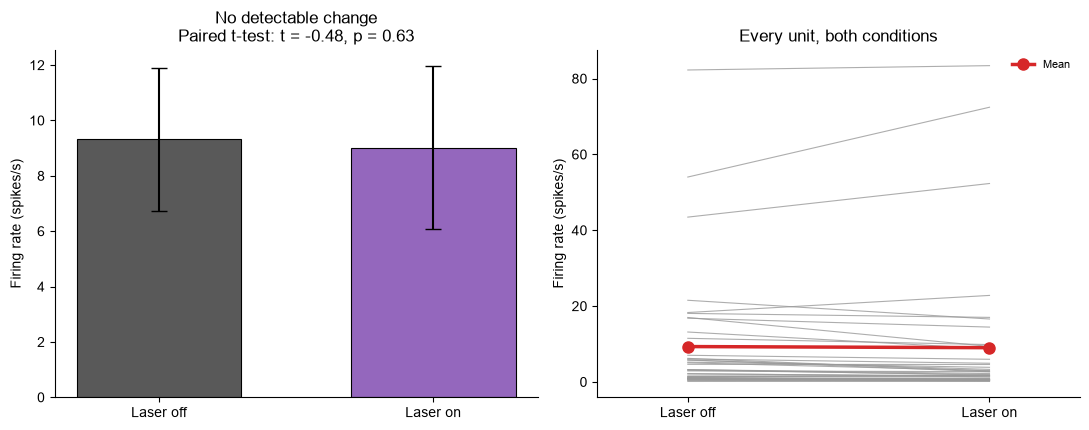

mean rate off : 9.314 spikes/s
mean rate on  : 9.019 spikes/s  (-3.2%)
mean paired difference: -0.295 spikes/s (SD 3.888)
paired t-test : t = -0.480, p = 0.634


In [3]:
res = stats.ttest_rel(on, off)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

means = [off.mean(), on.mean()]
sems  = [off.std(ddof=1)/np.sqrt(n_units), on.std(ddof=1)/np.sqrt(n_units)]
axes[0].bar([0, 1], means, yerr=sems, capsize=6, width=0.6,
            color=[C_OFF, C_ON], edgecolor='k', lw=0.8)
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(['Laser off', 'Laser on'])
axes[0].set_ylabel('Firing rate (spikes/s)')
axes[0].set_title(f'No detectable change\n'
                  f'Paired t-test: t = {res.statistic:.2f}, p = {res.pvalue:.2f}')

for i in range(n_units):
    axes[1].plot([0, 1], [off[i], on[i]], '-', color='0.6', lw=0.8, alpha=0.8)
axes[1].plot([0, 1], means, 'o-', color='tab:red', lw=2.5, ms=8, zorder=5,
             label='Mean')
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(['Laser off', 'Laser on'])
axes[1].set_xlim(-0.3, 1.3)
axes[1].set_ylabel('Firing rate (spikes/s)')
axes[1].set_title('Every unit, both conditions')
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print(f'mean rate off : {off.mean():.3f} spikes/s')
print(f'mean rate on  : {on.mean():.3f} spikes/s  '
      f'({(on.mean()/off.mean()-1)*100:+.1f}%)')
print(f'mean paired difference: {(on-off).mean():+.3f} spikes/s '
      f'(SD {(on-off).std(ddof=1):.3f})')
print(f'paired t-test : t = {res.statistic:.3f}, p = {res.pvalue:.3f}')


A difference of 0.3 spikes/s out of 9.3, and p = 0.63. On this evidence you would
write that the manipulation does nothing.

The manipulation does something. **What is the test missing, and what should you
have run instead?**
